# Classification Track — Vehicle Loan Default Prediction
23CSE301 ML Capstone

[Vehicle Loan Default Prediction](https://www.kaggle.com/datasets/mamtadhaker/lt-vehicle-loan-default-prediction) (`data/raw/train.csv`) — borrower and credit-bureau attributes for ~233k vehicle loans, with the goal of predicting whether the loan **defaults** (`loan_default`: 1) or not (0): a realistic, imbalanced binary credit-risk problem.

All 10 required classification algorithms are trained on the same preprocessed data, evaluated on the same stratified hold-out set, compared in one table, and the best model is tuned and exported for the GUI.

## Section A — Dataset & EDA

### A1. Dataset Loading & Audit

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="colorblind")

df = pd.read_csv("../data/raw/train.csv")
print("Shape:", df.shape)
df.info()

Shape: (233154, 41)
<class 'pandas.DataFrame'>
RangeIndex: 233154 entries, 0 to 233153
Data columns (total 41 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   UniqueID                             233154 non-null  int64  
 1   disbursed_amount                     233154 non-null  int64  
 2   asset_cost                           233154 non-null  int64  
 3   ltv                                  233154 non-null  float64
 4   branch_id                            233154 non-null  int64  
 5   supplier_id                          233154 non-null  int64  
 6   manufacturer_id                      233154 non-null  int64  
 7   Current_pincode_ID                   233154 non-null  int64  
 8   Date.of.Birth                        233154 non-null  str    
 9   Employment.Type                      225493 non-null  str    
 10  DisbursalDate                        233154 non-null  str    
 11  Stat

In [2]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nTarget (loan_default) balance:")
print(df["loan_default"].value_counts(normalize=True).rename("proportion"))

Missing values per column:
Employment.Type    7661
dtype: int64

Target (loan_default) balance:
loan_default
0    0.782929
1    0.217071
Name: proportion, dtype: float64


**Observation:** ~233k loan records, 41 columns, remarkably little missingness (only `Employment.Type`, ~3%). The target is **imbalanced**: ~78% of loans do not default, ~22% do. This matters for Section D — accuracy alone will be a misleading metric here, so weighted Precision/Recall/F1 and ROC-AUC matter more, and `class_weight="balanced"` is worth using in the classifiers that support it.

### A2. EDA Visualisations

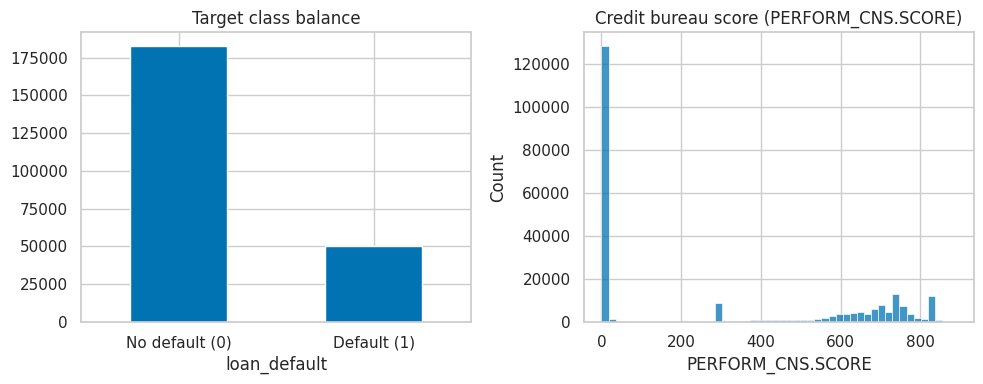

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["loan_default"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_xticklabels(["No default (0)", "Default (1)"], rotation=0)
axes[0].set_title("Target class balance")

sns.histplot(df["PERFORM_CNS.SCORE"], bins=50, ax=axes[1])
axes[1].set_title("Credit bureau score (PERFORM_CNS.SCORE)")
plt.tight_layout()
plt.show()

**Insight:** a large spike of `PERFORM_CNS.SCORE == 0` corresponds to borrowers with **no bureau history** (see the `PERFORM_CNS.SCORE.DESCRIPTION` column) rather than an actual score of zero — this needs to be treated as "no history" rather than a genuinely low score during preprocessing.

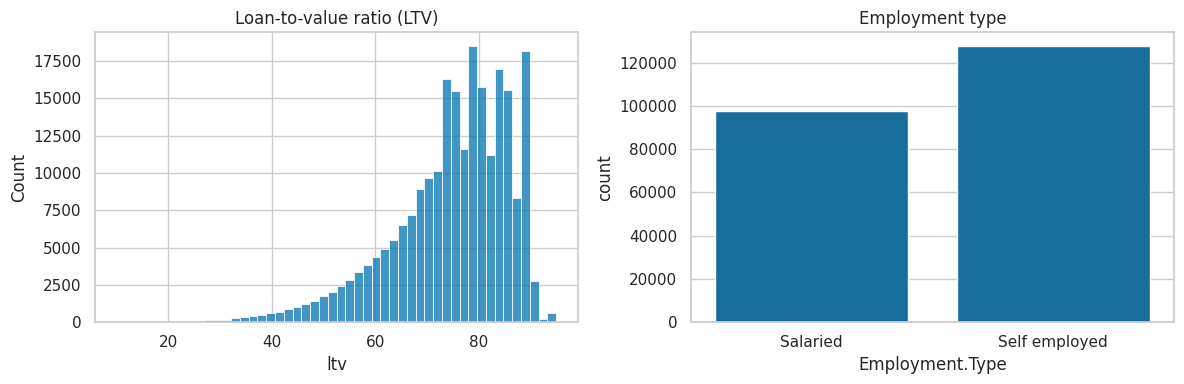

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["ltv"], bins=50, ax=axes[0]).set_title("Loan-to-value ratio (LTV)")
sns.countplot(data=df, x="Employment.Type", ax=axes[1]).set_title("Employment type")
plt.tight_layout()
plt.show()

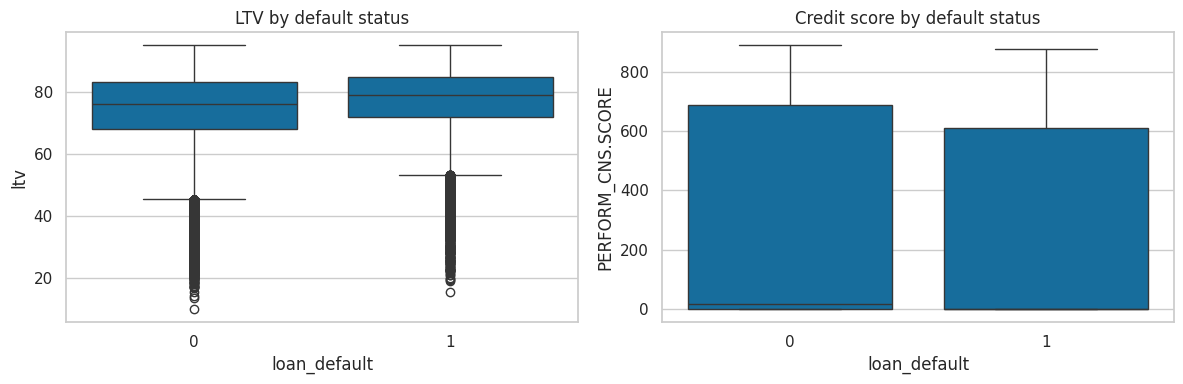

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="loan_default", y="ltv", ax=axes[0]).set_title("LTV by default status")
sns.boxplot(data=df, x="loan_default", y="PERFORM_CNS.SCORE", ax=axes[1]).set_title("Credit score by default status")
plt.tight_layout()
plt.show()

**Insight:** defaulted loans skew towards a *higher* loan-to-value ratio (borrower financed a larger share of the asset's cost, i.e. less 'skin in the game') — a well-known credit-risk signal. The credit-bureau score distributions overlap heavily between the two classes, though, which is a preview of why simple classifiers below (Section D) will only achieve modest separation: this is a genuinely hard dataset, not a toy one.

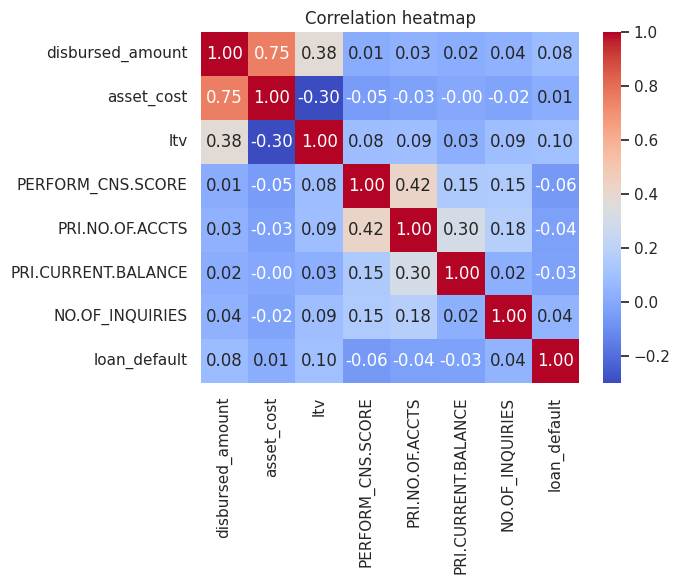

In [6]:
numeric_preview = ["disbursed_amount", "asset_cost", "ltv", "PERFORM_CNS.SCORE", "PRI.NO.OF.ACCTS", "PRI.CURRENT.BALANCE", "NO.OF_INQUIRIES", "loan_default"]
plt.figure(figsize=(7, 6))
sns.heatmap(df[numeric_preview].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

**Insight:** no single numeric feature correlates strongly with `loan_default` in isolation (all |r| well under 0.2) — consistent with the boxplot overlap above. This is a dataset where the signal is diffuse across many weak features rather than concentrated in one or two strong predictors, which is itself a useful, honest finding to report.

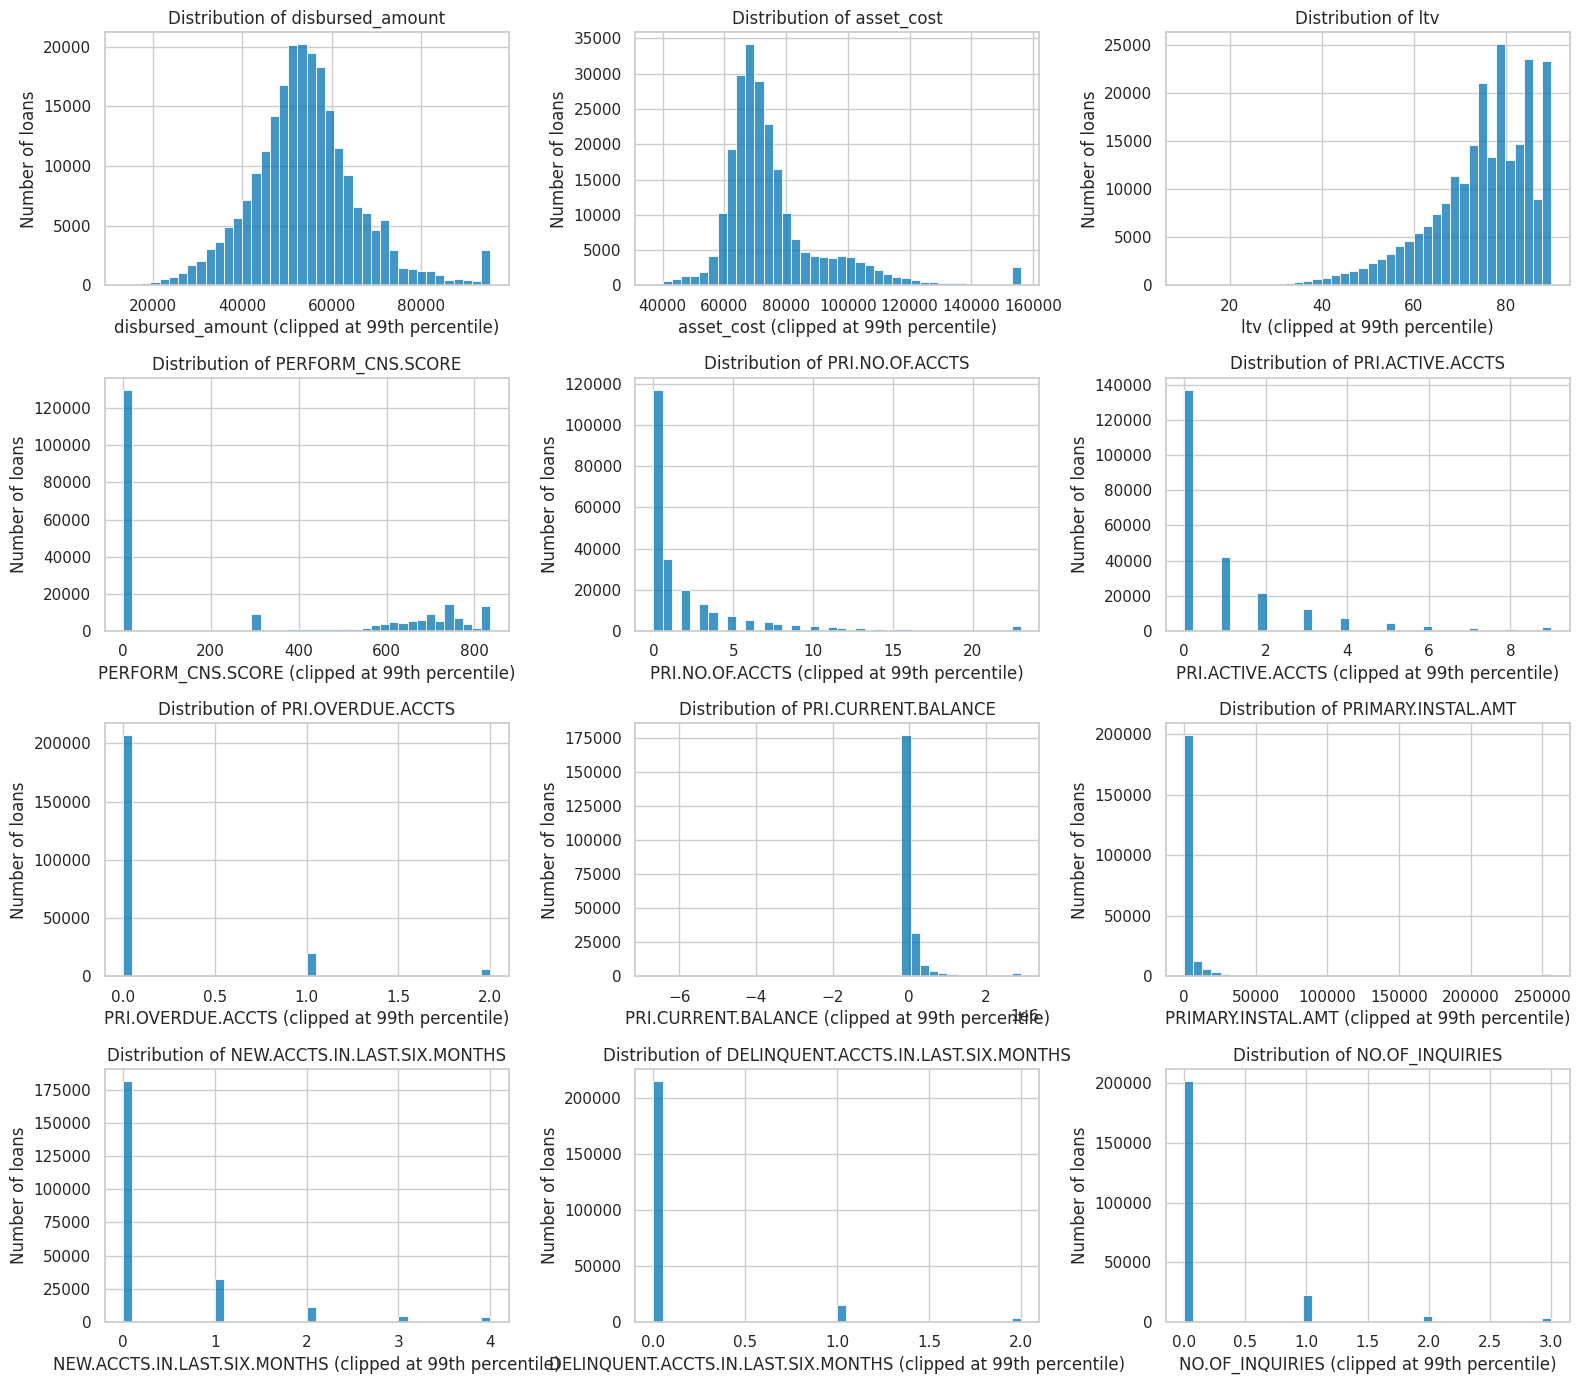

In [ ]:
# Distribution plots for every raw numeric feature (clipped at the 99th percentile so extreme tails don't flatten the plot)
eda_numeric = ["disbursed_amount", "asset_cost", "ltv", "PERFORM_CNS.SCORE", "PRI.NO.OF.ACCTS", "PRI.ACTIVE.ACCTS",
               "PRI.OVERDUE.ACCTS", "PRI.CURRENT.BALANCE", "PRIMARY.INSTAL.AMT", "NEW.ACCTS.IN.LAST.SIX.MONTHS",
               "DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS", "NO.OF_INQUIRIES"]
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.ravel(), eda_numeric):
    sns.histplot(df[col].clip(upper=df[col].quantile(0.99)), bins=40, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col + " (clipped at 99th percentile)")
    ax.set_ylabel("Number of loans")
plt.tight_layout()
plt.show()

**Observation:** the numeric features are far from normal. `disbursed_amount` is roughly bell-shaped around ₹50–55k with a modest right tail, `asset_cost` is right-skewed (peak ≈ ₹65–75k, long tail), and `ltv` is left-skewed, concentrated between about 70 % and 90 % and piling up at the upper cap. `PERFORM_CNS.SCORE` is strongly zero-inflated (over half of the loans are at 0, i.e. no bureau history), with a smaller group near 300 and a spread between about 600 and 840. The account and delinquency counts (`PRI.NO.OF.ACCTS`, `PRI.ACTIVE.ACCTS`, `PRI.OVERDUE.ACCTS`, `NEW.ACCTS.IN.LAST.SIX.MONTHS`, `DELINQUENT.ACCTS…`, `NO.OF_INQUIRIES`) are zero-inflated counts where most borrowers have 0 or 1. `PRI.CURRENT.BALANCE` and `PRIMARY.INSTAL.AMT` are extremely heavy-tailed, and the balance even takes negative values. (The tall bar at the right edge of some panels is an artefact of clipping at the 99th percentile.) Implications: scaling is essential for distance- and gradient-based models, tree models are insensitive to this skew, and the outliers are genuine records rather than errors, which is why they are kept.

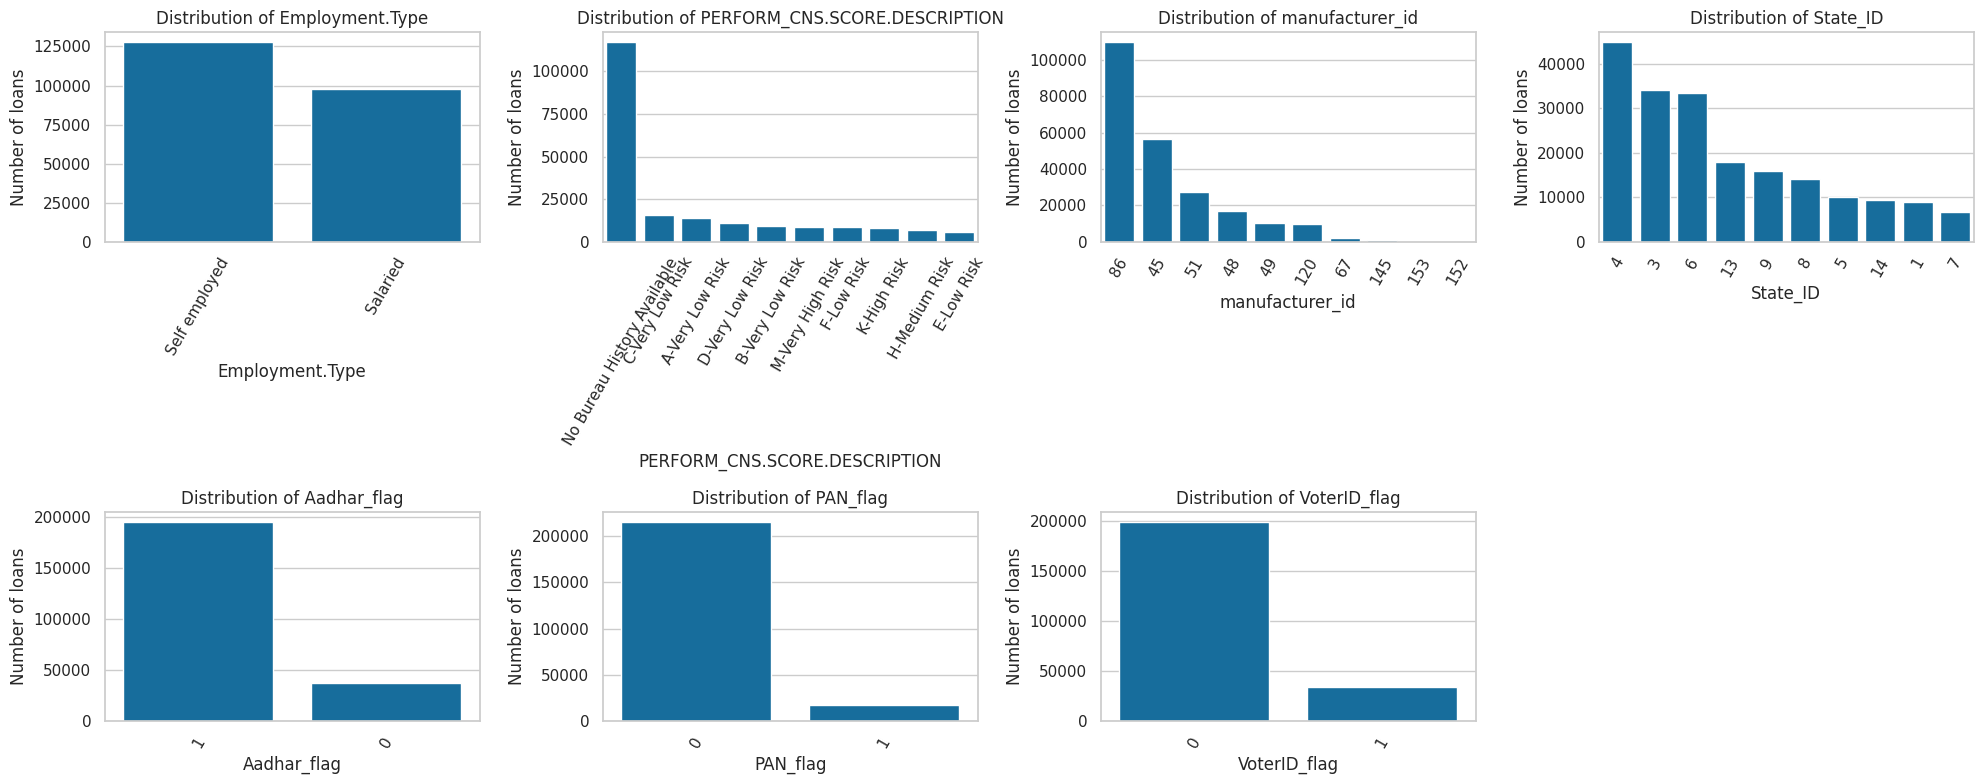

In [ ]:
# Distribution plots for the categorical / flag features
eda_cat = ["Employment.Type", "PERFORM_CNS.SCORE.DESCRIPTION", "manufacturer_id", "State_ID", "Aadhar_flag", "PAN_flag", "VoterID_flag"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), eda_cat):
    order = df[col].value_counts().head(10).index
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of loans")
    ax.tick_params(axis="x", rotation=60)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**Observation:** `Employment.Type` is split between self-employed (~128k) and salaried (~98k), with about 3 % missing. `PERFORM_CNS.SCORE.DESCRIPTION` is dominated by "No Bureau History Available" (~117k, about half of all loans), while the remaining risk bands (A to M) each hold only about 5–16k loans. `manufacturer_id` is concentrated in a few makers (id 86 ≈ 110k, id 45 ≈ 57k, id 51 ≈ 28k), and `State_ID` is led by states 4, 3 and 6 (≈ 33–45k each) with a long tail. The document flags are lopsided: most borrowers have `Aadhar_flag = 1` (~195k), but `PAN_flag = 1` (~17k) and `VoterID_flag = 1` (~33k) are the minority. Many one-hot columns will therefore be rare, and the "no bureau history" group is large enough to deserve its own treatment (the description column captures it).

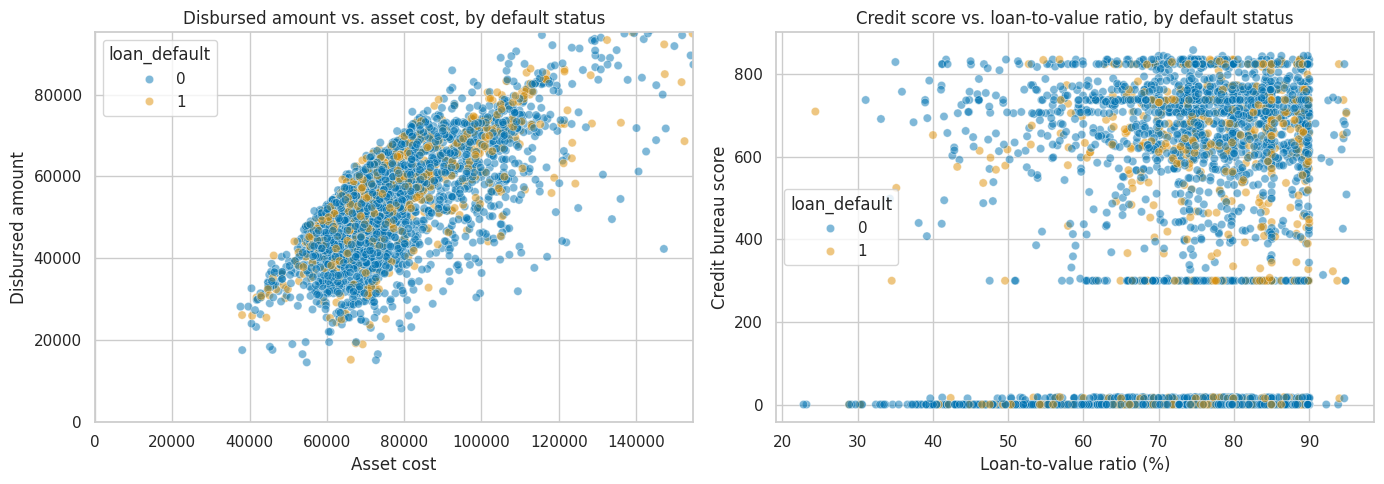

In [ ]:
# Feature-target scatter plots (coloured by loan_default, 5,000-loan random sample)
sample = df.sample(5000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=sample, x="asset_cost", y="disbursed_amount", hue="loan_default", alpha=0.5, ax=axes[0])
axes[0].set_title("Disbursed amount vs. asset cost, by default status")
axes[0].set_xlabel("Asset cost")
axes[0].set_ylabel("Disbursed amount")
axes[0].set_xlim(0, sample["asset_cost"].quantile(0.99)); axes[0].set_ylim(0, sample["disbursed_amount"].quantile(0.99))
axes[0].legend(title="loan_default")
sns.scatterplot(data=sample, x="ltv", y="PERFORM_CNS.SCORE", hue="loan_default", alpha=0.5, ax=axes[1])
axes[1].set_title("Credit score vs. loan-to-value ratio, by default status")
axes[1].set_xlabel("Loan-to-value ratio (%)")
axes[1].set_ylabel("Credit bureau score")
axes[1].legend(title="loan_default")
plt.tight_layout()
plt.show()

**Observation:** the scatter plots show little visible separation between defaulters (orange) and non-defaulters (blue). `disbursed_amount` rises almost linearly with `asset_cost` (loans are roughly 70–90 % of the asset price, which is what `ltv` measures), and the defaults are scattered through the whole band; if anything they are slightly more common at high loan-to-value, consistent with the boxplot. In the credit score vs LTV plot, scores fall into horizontal bands (0 = no history, about 300, and 600–840), and defaults appear in every band, again with only a mild tilt towards higher LTV. This confirms that no two features separate the classes cleanly, so a simple boundary between them will perform only modestly (as the model results show).

## Section B — Preprocessing & Feature Engineering

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

df_clean = df.copy()

# --- B3. Feature engineering: parse dates and duration strings into numeric features ---
# Date.of.Birth / DisbursalDate are dd-mm-yy; pandas' default 2-digit-year window can put some
# birth years in the future (e.g. "68" -> 2068) relative to the 2018 disbursal dates, so we
# correct any birth date that lands after its disbursal date back by 100 years.
dob = pd.to_datetime(df_clean["Date.of.Birth"], format="%d-%m-%y")
disb = pd.to_datetime(df_clean["DisbursalDate"], format="%d-%m-%y")
dob_fixed = dob.where(dob <= disb, dob - pd.DateOffset(years=100))
df_clean["age_years"] = (disb - dob_fixed).dt.days / 365.25

def parse_duration(s):
    # "1yrs 11mon" -> total months
    parts = s.replace("yrs", " ").replace("mon", " ").split()
    return int(parts[0]) * 12 + int(parts[1])

df_clean["avg_acct_age_months"] = df_clean["AVERAGE.ACCT.AGE"].apply(parse_duration)
df_clean["credit_history_months"] = df_clean["CREDIT.HISTORY.LENGTH"].apply(parse_duration)

# --- B1. Cleaning ---
# PERFORM_CNS.SCORE == 0 mostly means "no bureau history", not an actual low score;
# PERFORM_CNS.SCORE.DESCRIPTION already carries this distinction, so it's kept as a categorical feature.
# Employment.Type missingness is handled via imputation in the ColumnTransformer below (B2).

numeric_features = ["disbursed_amount", "asset_cost", "ltv", "age_years", "PERFORM_CNS.SCORE",
                     "PRI.NO.OF.ACCTS", "PRI.ACTIVE.ACCTS", "PRI.OVERDUE.ACCTS", "PRI.CURRENT.BALANCE",
                     "PRIMARY.INSTAL.AMT", "NEW.ACCTS.IN.LAST.SIX.MONTHS", "DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS",
                     "avg_acct_age_months", "credit_history_months", "NO.OF_INQUIRIES"]
categorical_features = ["Employment.Type", "PERFORM_CNS.SCORE.DESCRIPTION", "manufacturer_id", "State_ID",
                         "Aadhar_flag", "PAN_flag", "VoterID_flag"]
# Dropped: UniqueID, Date.of.Birth, DisbursalDate (superseded by age_years), AVERAGE.ACCT.AGE /
# CREDIT.HISTORY.LENGTH (superseded by the parsed *_months features), and branch_id / supplier_id /
# Current_pincode_ID / Employee_code_ID (too high-cardinality to one-hot encode meaningfully: 82 / 2,953 /
# 6,698 / 3,270 unique values respectively).

# Subsample for computational feasibility (SVC does not scale well on limited hardware)
df_model = df_clean.sample(n=8000, random_state=RANDOM_STATE).reset_index(drop=True)

X = df_model[numeric_features + categorical_features]
y = df_model["loan_default"]

# --- B2. Stratified split (important given the 78/22 class imbalance), then fit on train only ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
X_train_dense = X_train_proc.toarray() if hasattr(X_train_proc, "toarray") else X_train_proc
X_test_dense = X_test_proc.toarray() if hasattr(X_test_proc, "toarray") else X_test_proc

print("Train shape:", X_train_proc.shape, "Test shape:", X_test_proc.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True))

Train shape: (6400, 73) Test shape: (1600, 73)
Train class balance:
 loan_default
0    0.782188
1    0.217812
Name: proportion, dtype: float64


**B3 justification:**
- `age_years`: borrower's age at disbursal is a standard credit-risk feature; raw birth/disbursal date strings are not directly usable by any of the models.
- `avg_acct_age_months` / `credit_history_months`: converting `"1yrs 11mon"`-style strings to a single numeric (months) makes them usable by every model and comparable/orderable, unlike the raw string.

In [ ]:
# B1: duplicate and outlier checks
print("Duplicate UniqueID values:", df["UniqueID"].duplicated().sum())
print("Duplicate rows ignoring UniqueID:", df.drop(columns=["UniqueID"]).duplicated().sum())

q1, q3 = df_clean[numeric_features].quantile(0.25), df_clean[numeric_features].quantile(0.75)
iqr = q3 - q1
n_out = ((df_clean[numeric_features] < q1 - 1.5 * iqr) | (df_clean[numeric_features] > q3 + 1.5 * iqr)).sum()
outlier_table = pd.DataFrame({"outliers (1.5 x IQR rule)": n_out, "share of loans": (n_out / len(df_clean)).round(3)}).sort_values("share of loans", ascending=False)
display(outlier_table)

Duplicate UniqueID values: 0
Duplicate rows ignoring UniqueID: 0


,outliers (1.5 x IQR rule),share of loans
NEW.ACCTS.IN.LAST.SIX.MONTHS,51660,0.222
PRI.CURRENT.BALANCE,41044,0.176
PRIMARY.INSTAL.AMT,38868,0.167
PRI.ACTIVE.ACCTS,32534,0.140
NO.OF_INQUIRIES,31193,0.134
PRI.OVERDUE.ACCTS,26275,0.113
asset_cost,24388,0.105
PRI.NO.OF.ACCTS,21914,0.094
DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,18195,0.078
credit_history_months,16056,0.069


**B1 — duplicates, outliers and missing values (what the code does):**
- **Duplicates:** 0 duplicate `UniqueID` values and 0 duplicate rows (ignoring the ID) — nothing needs dropping.
- **Outliers:** flagged with the 1.5 × IQR rule in the table above. They are **retained, not removed or clipped**: the extreme values are genuine records (large loans, long credit histories, many accounts) rather than data-entry errors, the features are standardised, and the tree-based models are insensitive to magnitude.
- **Missing values:** only `Employment.Type` has gaps; it is imputed with the most frequent value inside the `ColumnTransformer` (train statistics only).

## Section C — Classification Models

### C1. Implementation — algorithms 1–10

Algorithms 1–5 (Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, SVC) come first, followed by an interim evaluation (C2); algorithms 6–10 (Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP) follow in C3, and everything is compared together in Section D.

Models use `X_train_proc` / `X_test_proc` (Gaussian NB needs the dense `X_train_dense` / `X_test_dense`). Given the 78/22 class imbalance, `class_weight="balanced"` (or balanced sample weights) is used wherever the estimator supports it.

Every fitted model is stored in `fitted_models[<name>]`, its predictions in `predictions[<name>]` and its **positive-class** probability in `probabilities[<name>]` (`model.predict_proba(X_test)[:, 1]`); Sections C2 and D read from these three dicts.

In [8]:
from sklearn.metrics import classification_report

fitted_models = {}
predictions = {}
probabilities = {}

**1. Logistic Regression** — Baseline classifier; interpret coefficients/odds. Consider class_weight=\"balanced\".

In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
model.fit(X_train_proc, y_train)
pred = model.predict(X_test_proc)
proba = model.predict_proba(X_test_proc)[:, 1]  # positive-class ("default") probability
fitted_models["Logistic Regression"] = model
predictions["Logistic Regression"] = pred
probabilities["Logistic Regression"] = proba

print(classification_report(y_test, pred, target_names=["No default", "Default"]))


              precision    recall  f1-score   support

  No default       0.82      0.54      0.65      1251
     Default       0.26      0.58      0.36       349

    accuracy                           0.55      1600
   macro avg       0.54      0.56      0.51      1600
weighted avg       0.70      0.55      0.59      1600



**1b. Logistic Regression — coefficients and odds ratios**

,coefficient,odds ratio
cat__State_ID_20,1.1026,3.0119
cat__PERFORM_CNS.SCORE.DESCRIPTION_L-Very High Risk,0.9209,2.5115
cat__PERFORM_CNS.SCORE.DESCRIPTION_M-Very High Risk,0.7392,2.0943
cat__PERFORM_CNS.SCORE.DESCRIPTION_B-Very Low Risk,-0.6590,0.5174
num__ltv,0.5309,1.7005
cat__State_ID_21,-0.5269,0.5904
cat__PERFORM_CNS.SCORE.DESCRIPTION_Not Scored: No Updates available in last 36 months,-0.4752,0.6218
cat__State_ID_18,-0.4613,0.6305
cat__PERFORM_CNS.SCORE.DESCRIPTION_No Bureau History Available,-0.4482,0.6388
cat__PERFORM_CNS.SCORE.DESCRIPTION_J-High Risk,0.4474,1.5643


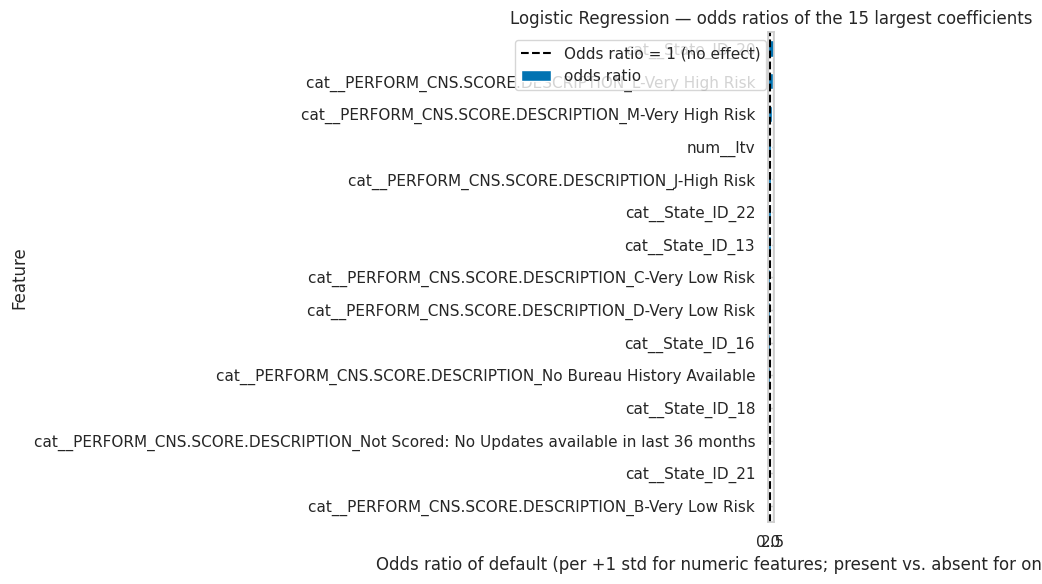

In [ ]:
feat_names = preprocessor.get_feature_names_out()
lr_model = fitted_models["Logistic Regression"]
lr_coef = pd.Series(lr_model.coef_[0], index=feat_names)
odds = pd.DataFrame({"coefficient": lr_coef, "odds ratio": np.exp(lr_coef)})
top_odds = odds.reindex(lr_coef.abs().sort_values(ascending=False).index).head(15)
display(top_odds.round(4))
plt.figure(figsize=(8, 6))
top_odds["odds ratio"].sort_values().plot(kind="barh")
plt.axvline(1, color="black", linestyle="--", label="Odds ratio = 1 (no effect)")
plt.title("Logistic Regression — odds ratios of the 15 largest coefficients")
plt.xlabel("Odds ratio of default (per +1 std for numeric features; present vs. absent for one-hot features)")
plt.ylabel("Feature")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** features with odds ratios above 1 raise the odds of default, below 1 lower them. Higher loan-to-value is the clearest numeric effect: +1 standard deviation of `ltv` multiplies the odds of default by about 1.70. Bureau risk bands behave as expected: the "Very High Risk" bands (L ≈ 2.51×, M ≈ 2.09×) and "High Risk" (J ≈ 1.56×) raise the odds, while the "Very Low Risk" bands (B ≈ 0.52×, C ≈ 0.70×, D ≈ 0.69×) lower them. Borrowers with "No Bureau History" or "Not Scored" have lower odds (≈ 0.64× and 0.62×) than the average category. Several `State_ID` dummies appear in the top 15 (State 20 ≈ 3.0×, State 21 ≈ 0.59×), but these rest on small groups in the 6,400-row training set and should be read as noisy. Even the strongest effects are modest in absolute terms, which matches the weak overall performance.

**2. KNN** — Tune k; discuss distance metrics.

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# Small sweep over k, scored by CV ROC-AUC on the training set only
best_k, best_score = None, -1
for k in [3, 5, 7, 9, 11, 15, 21]:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_proc, y_train, cv=3, scoring="roc_auc")
    if scores.mean() > best_score:
        best_k, best_score = k, scores.mean()
print(f"Selected k={best_k} (3-fold CV ROC-AUC={best_score:.4f})")
# Euclidean (Minkowski, p=2) distance is the sklearn default and used here; with one-hot-encoded
# categoricals mixed in, cosine or Manhattan distance would be reasonable alternatives to try.

model = KNeighborsClassifier(n_neighbors=best_k)
model.fit(X_train_proc, y_train)
pred = model.predict(X_test_proc)
proba = model.predict_proba(X_test_proc)[:, 1]  # positive-class ("default") probability
fitted_models["KNN"] = model
predictions["KNN"] = pred
probabilities["KNN"] = proba

print(classification_report(y_test, pred, target_names=["No default", "Default"]))


Selected k=21 (3-fold CV ROC-AUC=0.5757)
              precision    recall  f1-score   support

  No default       0.79      0.99      0.88      1251
     Default       0.52      0.03      0.06       349

    accuracy                           0.78      1600
   macro avg       0.65      0.51      0.47      1600
weighted avg       0.73      0.78      0.70      1600



**2b. KNN — comparing distance metrics**

In [ ]:
from sklearn.model_selection import cross_val_score
rows = []
for metric in ["euclidean", "manhattan", "chebyshev", "cosine"]:
    s = cross_val_score(KNeighborsClassifier(n_neighbors=best_k, metric=metric, algorithm="brute"), X_train_proc, y_train, cv=3, scoring="roc_auc")
    rows.append({"distance metric": metric, "3-fold CV ROC-AUC": s.mean(), "std": s.std()})
display(pd.DataFrame(rows).round(4))

,distance metric,3-fold CV ROC-AUC,std
0,euclidean,0.5757,0.0172
1,manhattan,0.5805,0.0116
2,chebyshev,0.5613,0.0182
3,cosine,0.5741,0.0138


**Interpretation:** Manhattan distance has the highest CV ROC-AUC (0.5805), followed by Euclidean (0.5757), cosine (0.5741) and Chebyshev (0.5613). The differences between the first three are within one standard deviation (≈ 0.012–0.018), so they are statistically indistinguishable; only Chebyshev is clearly worse. Manhattan is a sensible fit for this mix of standardised numeric features and 0/1 dummies: it sums the per-feature differences, so no single large difference dominates the way it can with Euclidean distance, and it is generally better behaved in higher dimensions (73 features here). Chebyshev uses only the single largest coordinate difference and ignores all the other features, which explains why it does worst.

**3. Gaussian Naive Bayes** — Discuss conditional independence assumption. Needs dense input: X_train_dense / X_test_dense.

In [11]:
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(X_train_dense, y_train)
pred = model.predict(X_test_dense)
proba = model.predict_proba(X_test_dense)[:, 1]  # positive-class ("default") probability
fitted_models["Gaussian Naive Bayes"] = model
predictions["Gaussian Naive Bayes"] = pred
probabilities["Gaussian Naive Bayes"] = proba

print(classification_report(y_test, pred, target_names=["No default", "Default"]))
# Conditional independence assumption: GaussianNB assumes every feature is independent given the
# class label. That's clearly false here (e.g. PRI.NO.OF.ACCTS and PRI.ACTIVE.ACCTS are correlated),
# so probability estimates are typically miscalibrated even when the resulting class ranking is decent.


              precision    recall  f1-score   support

  No default       0.83      0.09      0.17      1251
     Default       0.22      0.93      0.36       349

    accuracy                           0.28      1600
   macro avg       0.53      0.51      0.26      1600
weighted avg       0.70      0.28      0.21      1600



**3b. Gaussian Naive Bayes — how realistic is the conditional-independence assumption?**

In [ ]:
corr = X_train[numeric_features].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
print(f"{(pairs > 0.7).sum()} of {len(pairs)} numeric feature pairs have |correlation| > 0.7 (Gaussian NB treats all features as independent given the class)")
display(pairs.head(8).round(3).to_frame("|correlation|"))

3 of 225 numeric feature pairs have |correlation| > 0.7 (Gaussian NB treats all features as independent given the class)


|correlation|
avg_acct_age_months credit_history_months                 0.834
PRI.NO.OF.ACCTS     PRI.ACTIVE.ACCTS                      0.811
disbursed_amount    asset_cost                            0.733
PRI.ACTIVE.ACCTS    NEW.ACCTS.IN.LAST.SIX.MONTHS          0.577
PRI.NO.OF.ACCTS     NEW.ACCTS.IN.LAST.SIX.MONTHS          0.547
PRI.ACTIVE.ACCTS    PRI.CURRENT.BALANCE                   0.491
PERFORM_CNS.SCORE   avg_acct_age_months                   0.486
                    credit_history_months                 0.482

**Interpretation:** the numeric features are mostly not strongly correlated (only 3 of 225 pairs exceed |r| = 0.7: `avg_acct_age_months` with `credit_history_months` at 0.83, `PRI.NO.OF.ACCTS` with `PRI.ACTIVE.ACCTS` at 0.81, `disbursed_amount` with `asset_cost` at 0.73), so the independence assumption is only mildly violated for the numeric block. It is violated far more by the one-hot dummies (mutually exclusive within a group) and by the Gaussian assumption for count and binary features. The result shows the damage: the model predicts "default" for almost everything (default recall 0.93, but no-default recall 0.09, accuracy 0.28). Repeated, correlated evidence is multiplied as if independent, pushing the posterior probabilities to extremes (miscalibration). Importantly, its ROC-AUC (0.573) is on par with the other models, so the *ranking* of borrowers is as good as the others; only the probability scale and decision threshold are off.

**4. Decision Tree Classifier** — Tune max_depth; visualise the tree. Consider class_weight=\"balanced\".

Selected max_depth=5 (3-fold CV ROC-AUC=0.5628)
              precision    recall  f1-score   support

  No default       0.81      0.47      0.60      1251
     Default       0.24      0.61      0.35       349

    accuracy                           0.50      1600
   macro avg       0.53      0.54      0.47      1600
weighted avg       0.69      0.50      0.54      1600



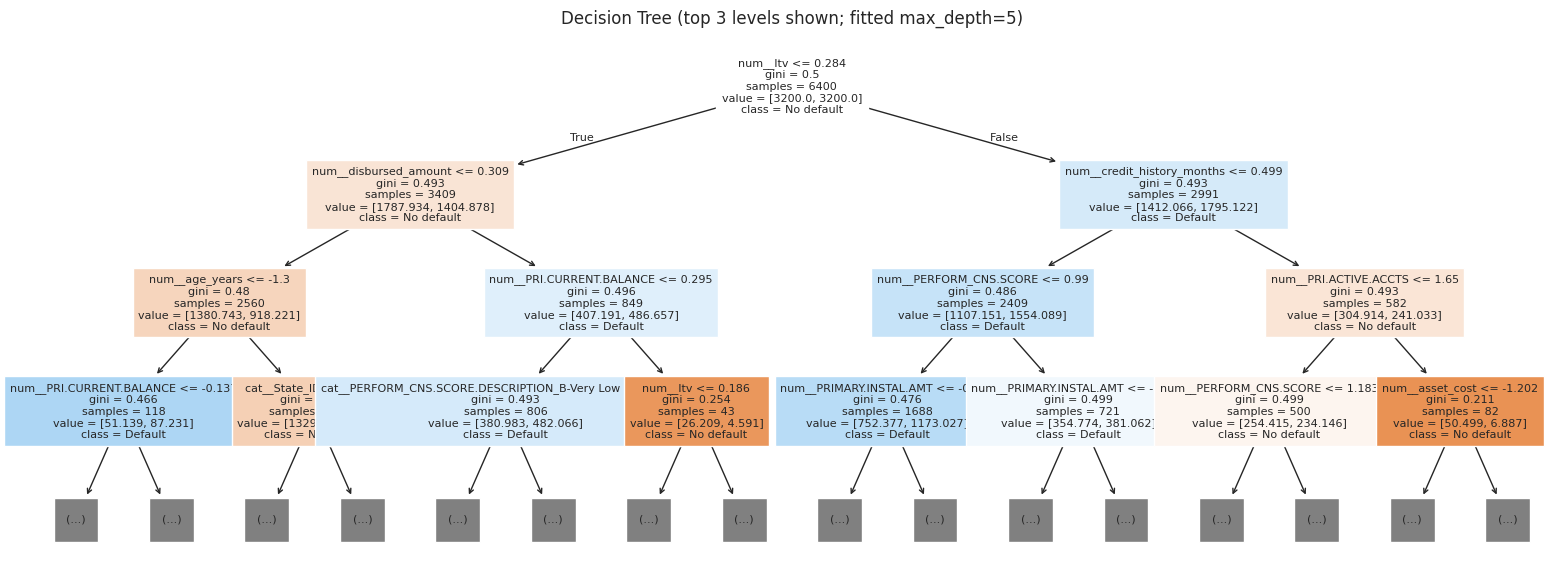

In [12]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score

# Small sweep over max_depth, scored by CV ROC-AUC on the training set only
best_depth, best_score = None, -1
for depth in [3, 5, 7, 10, 15, None]:
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=RANDOM_STATE),
        X_train_proc, y_train, cv=3, scoring="roc_auc",
    )
    if scores.mean() > best_score:
        best_depth, best_score = depth, scores.mean()
print(f"Selected max_depth={best_depth} (3-fold CV ROC-AUC={best_score:.4f})")

model = DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=RANDOM_STATE)
model.fit(X_train_proc, y_train)
pred = model.predict(X_test_proc)
proba = model.predict_proba(X_test_proc)[:, 1]  # positive-class ("default") probability
fitted_models["Decision Tree Classifier"] = model
predictions["Decision Tree Classifier"] = pred
probabilities["Decision Tree Classifier"] = proba

print(classification_report(y_test, pred, target_names=["No default", "Default"]))

feature_names = preprocessor.get_feature_names_out()
plt.figure(figsize=(16, 6))
plot_tree(model, max_depth=3, feature_names=feature_names, class_names=["No default", "Default"],
          filled=True, fontsize=8)
plt.title(f"Decision Tree (top 3 levels shown; fitted max_depth={best_depth})")
plt.tight_layout()
plt.show()


**5. SVC** — Tune C and kernel; scale features (already done in Section B). Remember probability=True for ROC-AUC and consider class_weight=\"balanced\".

In [13]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV

# Wrapping SVC in CalibratedClassifierCV (rather than SVC(probability=True) directly) gives
# better-calibrated probability estimates for ROC-AUC, and plays more predictably with GridSearchCV.
param_grid = {"estimator__C": [0.1, 1, 10], "estimator__kernel": ["rbf", "linear"]}
grid = GridSearchCV(
    CalibratedClassifierCV(SVC(class_weight="balanced", random_state=RANDOM_STATE), ensemble=False),
    param_grid, cv=3, scoring="roc_auc", n_jobs=-1,
)
grid.fit(X_train_proc, y_train)
print("Best SVC params:", grid.best_params_, f"(3-fold CV ROC-AUC={grid.best_score_:.4f})")

model = grid.best_estimator_
pred = model.predict(X_test_proc)
proba = model.predict_proba(X_test_proc)[:, 1]  # positive-class ("default") probability
fitted_models["SVC"] = model
predictions["SVC"] = pred
probabilities["SVC"] = proba

print(classification_report(y_test, pred, target_names=["No default", "Default"]))


Best SVC params: {'estimator__C': 0.1, 'estimator__kernel': 'linear'} (3-fold CV ROC-AUC=0.6223)


              precision    recall  f1-score   support

  No default       0.78      1.00      0.88      1251
     Default       0.33      0.00      0.01       349

    accuracy                           0.78      1600
   macro avg       0.56      0.50      0.44      1600
weighted avg       0.68      0.78      0.69      1600



### C2. Interim evaluation — algorithms 1–5

Accuracy, Precision, Recall, weighted F1 and ROC-AUC for the first five models, plus a confusion matrix for every one of them. The full 10-model comparison is in Section D.

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

rows = []
for name in fitted_models:
    pred = predictions[name]
    proba = probabilities[name]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted"),
        "Recall": recall_score(y_test, pred, average="weighted"),
        "F1 (weighted)": f1_score(y_test, pred, average="weighted"),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

if rows:
    partA_results = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
    print(partA_results)
else:
    print("No models fitted yet — run the algorithm cells above first.")

                      Model  Accuracy  Precision   Recall  F1 (weighted)  \
0       Logistic Regression   0.55125   0.700641  0.55125       0.590247   
1      Gaussian Naive Bayes   0.27625   0.701171  0.27625       0.209073   
2                       SVC   0.78125   0.684206  0.78125       0.687027   
3  Decision Tree Classifier   0.50125   0.688304  0.50125       0.542034   
4                       KNN   0.78250   0.728595  0.78250       0.699734   

    ROC-AUC  
0  0.578739  
1  0.572972  
2  0.570959  
3  0.560020  
4  0.554831  


Best model among algorithms 1–5 by ROC-AUC: Logistic Regression


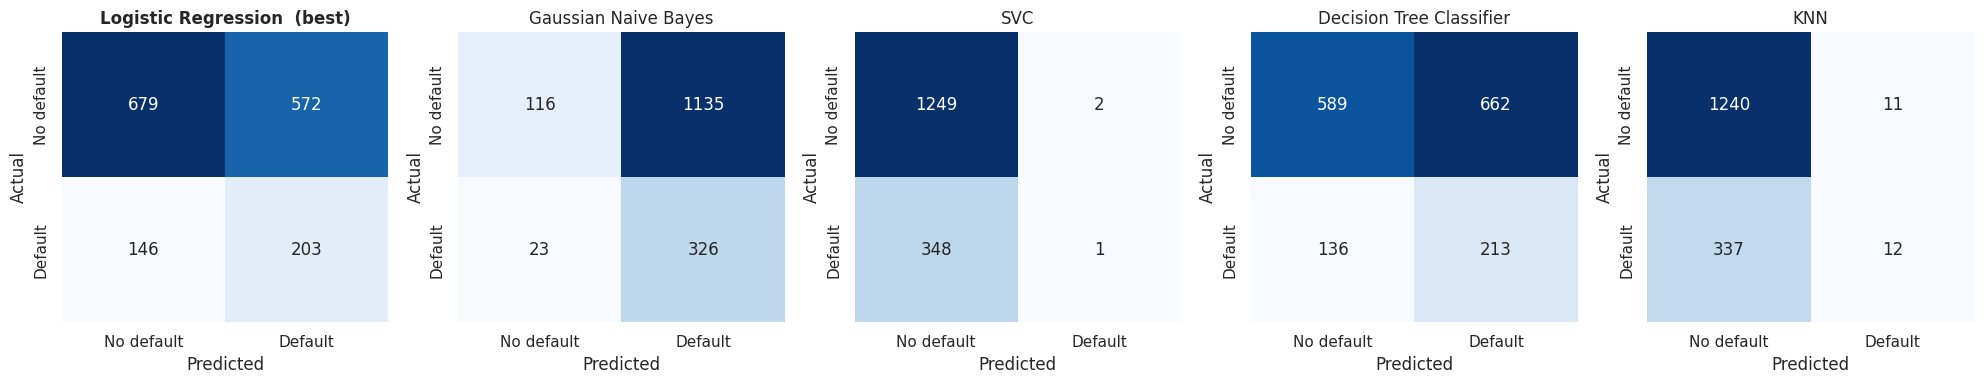

In [15]:
# Confusion matrix for every algorithm 1–5 model (one matrix per algorithm),
# with the best model (by ROC-AUC) called out explicitly.
best_name = partA_results.iloc[0]["Model"]
print(f"Best model among algorithms 1–5 by ROC-AUC: {best_name}")

model_order = partA_results["Model"].tolist()
fig, axes = plt.subplots(1, len(model_order), figsize=(4 * len(model_order), 4))
for ax, name in zip(axes, model_order):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No default", "Default"], yticklabels=["No default", "Default"], ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    title = name + ("  (best)" if name == best_name else "")
    ax.set_title(title, fontweight="bold" if name == best_name else "normal")
plt.tight_layout()
plt.show()


### C3. Implementation — algorithms 6–10

The same three dicts (`fitted_models`, `predictions`, `probabilities`) are extended with algorithms 6–10, using the same `X_train_proc` / `X_test_proc` split and `random_state=RANDOM_STATE` (all ten algorithms must be evaluated on identical data). `probabilities[<name>]` is the positive-class probability, `model.predict_proba(X_test_proc)[:, 1]`.

Imbalance handling: `RandomForestClassifier` and the decision-tree base estimators use class weights; AdaBoost and Gradient Boosting use balanced sample weights.

**6. Random Forest Classifier** — Feature importance; tune n_estimators.

3-fold CV ROC-AUC by n_estimators: {100: np.float64(0.6116), 200: np.float64(0.6129), 400: np.float64(0.6132)}


Final Random Forest: n_estimators = 400
              precision    recall  f1-score   support

  No default       0.80      0.71      0.75      1251
     Default       0.26      0.37      0.30       349

    accuracy                           0.63      1600
   macro avg       0.53      0.54      0.53      1600
weighted avg       0.68      0.63      0.65      1600



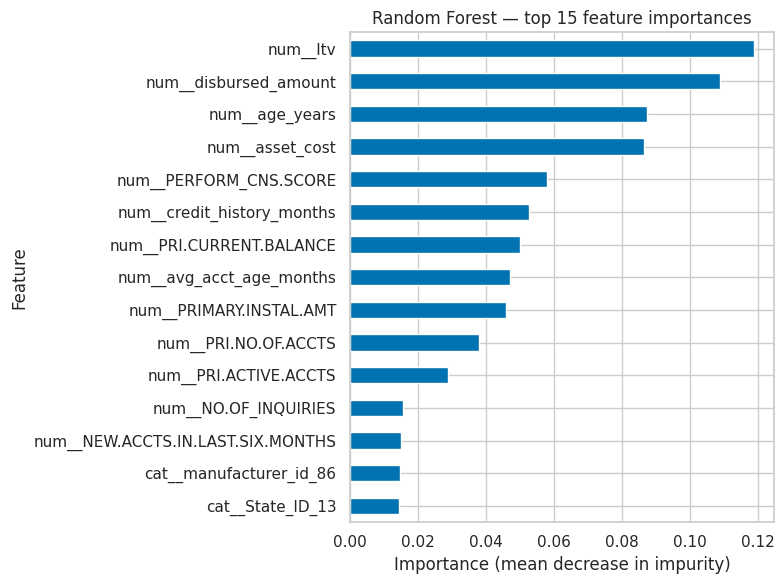

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report

# Tune n_estimators with 3-fold CV ROC-AUC on the training set only (class_weight handles the 78/22 imbalance)
rf_cv = {}
for n_est in [100, 200, 400]:
    rf = RandomForestClassifier(n_estimators=n_est, max_depth=12, min_samples_leaf=5,
                                class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1)
    rf_cv[n_est] = cross_val_score(rf, X_train_proc, y_train, cv=3, scoring="roc_auc").mean()
print("3-fold CV ROC-AUC by n_estimators:", {k: round(v, 4) for k, v in rf_cv.items()})
best_n = max(rf_cv, key=rf_cv.get)

model = RandomForestClassifier(n_estimators=best_n, max_depth=12, min_samples_leaf=5,
                               class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1)
model.fit(X_train_proc, y_train)
pred = model.predict(X_test_proc)
proba = model.predict_proba(X_test_proc)[:, 1]  # positive-class ("default") probability
fitted_models["Random Forest Classifier"] = model
predictions["Random Forest Classifier"] = pred
probabilities["Random Forest Classifier"] = proba
print(f"Final Random Forest: n_estimators = {best_n}")
print(classification_report(y_test, pred, target_names=["No default", "Default"]))

# Feature importance (top 15)
importances = pd.Series(model.feature_importances_, index=preprocessor.get_feature_names_out()).sort_values().tail(15)
plt.figure(figsize=(8, 6))
importances.plot(kind="barh")
plt.title("Random Forest — top 15 feature importances")
plt.xlabel("Importance (mean decrease in impurity)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**7. AdaBoost Classifier** — Tune n_estimators and learning_rate.

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report

# AdaBoost has no class_weight option, so the imbalance is handled with balanced sample weights
sw_train = compute_sample_weight("balanced", y_train)
param_grid = {"n_estimators": [50, 100, 200], "learning_rate": [0.05, 0.1, 0.5]}
grid = GridSearchCV(AdaBoostClassifier(random_state=RANDOM_STATE), param_grid, cv=3, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train_proc, y_train, sample_weight=sw_train)
print("Best AdaBoost params:", grid.best_params_, f"(3-fold CV ROC-AUC = {grid.best_score_:.4f})")

model = grid.best_estimator_
pred = model.predict(X_test_proc)
proba = model.predict_proba(X_test_proc)[:, 1]  # positive-class ("default") probability
fitted_models["AdaBoost Classifier"] = model
predictions["AdaBoost Classifier"] = pred
probabilities["AdaBoost Classifier"] = proba
print(classification_report(y_test, pred, target_names=["No default", "Default"]))

Best AdaBoost params: {'learning_rate': 0.5, 'n_estimators': 200} (3-fold CV ROC-AUC = 0.6070)
              precision    recall  f1-score   support

  No default       0.82      0.53      0.64      1251
     Default       0.25      0.57      0.35       349

    accuracy                           0.54      1600
   macro avg       0.53      0.55      0.50      1600
weighted avg       0.69      0.54      0.58      1600



**8. Gradient Boosting Classifier** — sklearn GBM or XGBoost/LightGBM.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report

# sklearn GBM; shallow trees + subsampling + a small learning rate to limit overfitting on weak signal
sw_train = compute_sample_weight("balanced", y_train)
model = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8,
                                   random_state=RANDOM_STATE)
model.fit(X_train_proc, y_train, sample_weight=sw_train)
pred = model.predict(X_test_proc)
proba = model.predict_proba(X_test_proc)[:, 1]  # positive-class ("default") probability
fitted_models["Gradient Boosting Classifier"] = model
predictions["Gradient Boosting Classifier"] = pred
probabilities["Gradient Boosting Classifier"] = proba
print(classification_report(y_test, pred, target_names=["No default", "Default"]))

              precision    recall  f1-score   support

  No default       0.80      0.58      0.68      1251
     Default       0.25      0.49      0.33       349

    accuracy                           0.56      1600
   macro avg       0.53      0.54      0.50      1600
weighted avg       0.68      0.56      0.60      1600



**9. Bagging Classifier** — Use Decision Tree as base estimator (e.g. `BaggingClassifier(estimator=DecisionTreeClassifier(...))`).

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# Bagging with a Decision Tree base estimator; balanced class weights inside each tree
model = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, class_weight="balanced", random_state=RANDOM_STATE),
    n_estimators=100, max_samples=0.8, random_state=RANDOM_STATE, n_jobs=-1,
)
model.fit(X_train_proc, y_train)
pred = model.predict(X_test_proc)
proba = model.predict_proba(X_test_proc)[:, 1]  # positive-class ("default") probability
fitted_models["Bagging Classifier"] = model
predictions["Bagging Classifier"] = pred
probabilities["Bagging Classifier"] = proba
print(classification_report(y_test, pred, target_names=["No default", "Default"]))

              precision    recall  f1-score   support

  No default       0.81      0.66      0.73      1251
     Default       0.26      0.43      0.33       349

    accuracy                           0.61      1600
   macro avg       0.53      0.55      0.53      1600
weighted avg       0.69      0.61      0.64      1600



**10. MLP Classifier** — Tune hidden layer sizes and activation.

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# Tune hidden layer sizes and activation (3-fold CV ROC-AUC); early stopping keeps training short and limits overfitting
param_grid = {"hidden_layer_sizes": [(32,), (64, 32)], "activation": ["relu", "tanh"]}
grid = GridSearchCV(
    MLPClassifier(alpha=1e-3, early_stopping=True, max_iter=300, random_state=RANDOM_STATE),
    param_grid, cv=3, scoring="roc_auc", n_jobs=-1,
)
grid.fit(X_train_proc, y_train)
print("Best MLP params:", grid.best_params_, f"(3-fold CV ROC-AUC = {grid.best_score_:.4f})")

model = grid.best_estimator_
pred = model.predict(X_test_proc)
proba = model.predict_proba(X_test_proc)[:, 1]  # positive-class ("default") probability
fitted_models["MLP Classifier"] = model
predictions["MLP Classifier"] = pred
probabilities["MLP Classifier"] = proba
print(classification_report(y_test, pred, target_names=["No default", "Default"]))

Best MLP params: {'activation': 'tanh', 'hidden_layer_sizes': (64, 32)} (3-fold CV ROC-AUC = 0.5975)
              precision    recall  f1-score   support

  No default       0.78      1.00      0.88      1251
     Default       0.50      0.00      0.01       349

    accuracy                           0.78      1600
   macro avg       0.64      0.50      0.44      1600
weighted avg       0.72      0.78      0.69      1600



## Section D — Evaluation & Model Selection

### D1. Consolidated comparison — all 10 algorithms

A **single** table comparing all ten algorithms on Accuracy, Precision, Recall, F1 and ROC-AUC.

In [ ]:
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

ALL_10 = ["Logistic Regression", "KNN", "Gaussian Naive Bayes", "Decision Tree Classifier", "SVC",
          "Random Forest Classifier", "AdaBoost Classifier", "Gradient Boosting Classifier",
          "Bagging Classifier", "MLP Classifier"]

missing = [m for m in ALL_10 if m not in fitted_models]
if missing:
    print("TODO: these algorithms are not in fitted_models yet:", missing)
else:
    rows = []
    for name in ALL_10:
        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions[name]),
            "Precision": precision_score(y_test, predictions[name], average="weighted"),
            "Recall": recall_score(y_test, predictions[name], average="weighted"),
            "F1 (weighted)": f1_score(y_test, predictions[name], average="weighted"),
            "ROC-AUC": roc_auc_score(y_test, probabilities[name]),
        })
    full_results = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
    display(full_results)

,Model,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC
0,Random Forest Classifier,0.634375,0.682671,0.634375,0.654378,0.578966
1,Logistic Regression,0.551250,0.700641,0.551250,0.590247,0.578739
2,MLP Classifier,0.781875,0.720667,0.781875,0.687339,0.577775
3,Gaussian Naive Bayes,0.276250,0.701171,0.276250,0.209073,0.572972
4,Gradient Boosting Classifier,0.562500,0.682938,0.562500,0.599892,0.572578
5,AdaBoost Classifier,0.540625,0.692772,0.540625,0.580491,0.572057
6,Bagging Classifier,0.611250,0.688121,0.611250,0.639491,0.571243
7,SVC,0.781250,0.684206,0.781250,0.687027,0.570959
8,Decision Tree Classifier,0.501250,0.688304,0.501250,0.542034,0.560020
9,KNN,0.782500,0.728595,0.782500,0.699734,0.554831


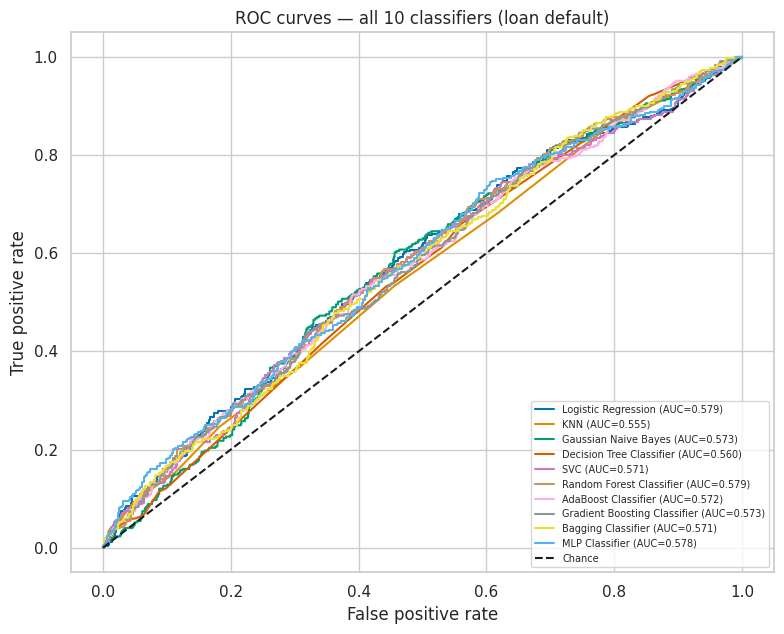

In [ ]:
# ROC curves for all 10 classifiers on one set of axes (needs all ten models (algorithms 1–10))
from sklearn.metrics import roc_curve

if not missing:
    plt.figure(figsize=(8, 6.5))
    for name in ALL_10:
        fpr, tpr, _ = roc_curve(y_test, probabilities[name])
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probabilities[name]):.3f})")
    plt.plot([0, 1], [0, 1], "k--", label="Chance")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("ROC curves — all 10 classifiers (loan default)")
    plt.legend(fontsize=7, loc="lower right")
    plt.tight_layout()
    plt.show()
else:
    print("ROC curves will appear once all 10 models are in fitted_models (see A2).")

**Observation:** all ten models are close in ranking power: ROC-AUC runs from 0.555 (KNN) to 0.579 (Random Forest), a spread of only about 0.024, with Logistic Regression (0.579), MLP (0.578) and Gaussian NB (0.573) in the top group. That is only slightly better than chance (0.5), and on a 1,600-row test set with 349 defaulters such small gaps are within noise. Accuracy is misleading here: the highest values (KNN 0.783, MLP 0.782, SVC 0.781) simply equal the share of non-defaulters (≈ 78 %), because these models predict "no default" for almost everybody (default recall 0.00–0.03). Models trained with class balancing score lower accuracy (0.50–0.63) but actually catch 40–60 % of defaulters, and Gaussian NB has the lowest accuracy (0.276) while its AUC is among the best. Weighted F1 shows the same bias towards majority-class predictors, so ROC-AUC and per-class recall are the more honest measures for this imbalanced problem.

### D3. Final model selection & hyperparameter tuning

The best model is identified from the consolidated table, tuned with `GridSearchCV` (small grids), and the before/after metrics are reported; 5-fold cross-validation is run for the two best-performing models and the final model is exported to `models/best_classifier.joblib` for the GUI.

In [ ]:
# Final model = the best model by ROC-AUC in the consolidated table, tuned with GridSearchCV (small grids: single-core friendly)
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import joblib, os

TUNING_GRIDS = {
    "Logistic Regression":          {"C": [0.01, 0.1, 1, 10]},
    "KNN":                          {"n_neighbors": [5, 15, 31], "weights": ["uniform", "distance"]},
    "Gaussian Naive Bayes":         {"var_smoothing": [1e-9, 1e-7, 1e-5]},
    "Decision Tree Classifier":     {"max_depth": [3, 5, 8], "min_samples_leaf": [1, 20]},
    "SVC":                          {"estimator__C": [0.5, 1, 2]},   # SVC is a CalibratedClassifierCV(SVC) from the first group of models
    "Random Forest Classifier":     {"n_estimators": [100], "max_depth": [6, 12], "min_samples_leaf": [1, 10]},
    "AdaBoost Classifier":          {"n_estimators": [50, 150], "learning_rate": [0.05, 0.5]},
    "Gradient Boosting Classifier": {"n_estimators": [100], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]},
    "Bagging Classifier":           {"n_estimators": [20, 50], "max_samples": [0.5, 1.0]},
    "MLP Classifier":               {"hidden_layer_sizes": [(32,), (64, 32)], "alpha": [1e-4, 1e-2]},
}

if not missing:
    best_name = full_results.iloc[0]["Model"]
    print("Best model by ROC-AUC:", best_name)
    dense = best_name == "Gaussian Naive Bayes"                   # GaussianNB needs dense input
    Xtr_best = X_train_dense if dense else X_train_proc
    Xte_best = X_test_dense if dense else X_test_proc

    search = GridSearchCV(clone(fitted_models[best_name]), TUNING_GRIDS[best_name], cv=3, scoring="roc_auc", n_jobs=-1)
    search.fit(Xtr_best, y_train)
    tuned = search.best_estimator_
    tuned_pred = tuned.predict(Xte_best)
    tuned_proba = tuned.predict_proba(Xte_best)[:, 1]
    print("Best params:", search.best_params_, f"(3-fold CV ROC-AUC = {search.best_score_:.4f})")

    before = full_results.iloc[0]
    comparison = pd.DataFrame({
        "Metric": ["Accuracy", "F1 (weighted)", "ROC-AUC"],
        "Before tuning": [before["Accuracy"], before["F1 (weighted)"], before["ROC-AUC"]],
        "After tuning": [accuracy_score(y_test, tuned_pred), f1_score(y_test, tuned_pred, average="weighted"),
                         roc_auc_score(y_test, tuned_proba)],
    })
    comparison["Change"] = comparison["After tuning"] - comparison["Before tuning"]
    display(comparison)

    # Keep the better of {untuned, tuned} on test ROC-AUC as the final model, and save it for the GUI (app/app.py)
    final_model = tuned if comparison.loc[2, "After tuning"] >= comparison.loc[2, "Before tuning"] else fitted_models[best_name]
    os.makedirs("../models", exist_ok=True)
    joblib.dump(Pipeline([("pre", preprocessor), ("clf", final_model)]), "../models/best_classifier.joblib")
    print("Saved ../models/best_classifier.joblib")
else:
    print("Final selection + tuning run once all 10 models are in fitted_models (see A2).")

Best model by ROC-AUC: Random Forest Classifier


Best params: {'max_depth': 6, 'min_samples_leaf': 10, 'n_estimators': 100} (3-fold CV ROC-AUC = 0.6150)


,Metric,Before tuning,After tuning,Change
0,Accuracy,0.634375,0.574375,-0.060000
1,F1 (weighted),0.654378,0.610969,-0.043409
2,ROC-AUC,0.578966,0.586404,0.007438


Saved ../models/best_classifier.joblib


In [ ]:
# 5-fold cross-validated ROC-AUC for the two best-performing models
from sklearn.model_selection import cross_val_score

if not missing:
    for name in full_results["Model"].head(2):
        Xcv = X_train_dense if name == "Gaussian Naive Bayes" else X_train_proc
        scores = cross_val_score(clone(fitted_models[name]), Xcv, y_train, cv=5, scoring="roc_auc")
        print(f"{name}: 5-fold CV ROC-AUC = {scores.mean():.4f} (+/- {scores.std():.4f})")
else:
    print("Cross-validation runs once all 10 models are in fitted_models (see A2).")

Random Forest Classifier: 5-fold CV ROC-AUC = 0.6179 (+/- 0.0125)


Logistic Regression: 5-fold CV ROC-AUC = 0.6300 (+/- 0.0136)


**Justification for the final model:** Random Forest was selected as the model with the highest test ROC-AUC (0.579). Tuning (`max_depth = 6`, `min_samples_leaf = 10`, 100 trees) raised ROC-AUC slightly to 0.586 (3-fold CV 0.615), so the tuned model was kept and exported for the GUI; accuracy and weighted F1 fell (0.634 → 0.574 and 0.654 → 0.611) because the shallower, class-balanced forest labels more borrowers as defaulters, which is a threshold effect rather than worse ranking. A forest handles mixed numeric and one-hot features, needs no feature scaling, and offers feature importances: `ltv`, `disbursed_amount`, `age_years` and `asset_cost` lead. Honest caveat: on 5-fold CV, Logistic Regression (0.630 ± 0.014) is actually slightly ahead of Random Forest (0.618 ± 0.013), a gap of about one standard deviation, so the ranking between them is not reliable. Logistic Regression is simpler, cheaper to train and interpretable through odds ratios, and would be a defensible alternative; the Random Forest choice rests on the test-split ranking and its flexibility.

## Conclusion

**Problem.** Predict whether a vehicle loan will default (`loan_default`), an imbalanced binary credit-risk problem (≈ 78 % no default, 22 % default).

**Data.** The L&T Vehicle Loan Default dataset has about 233k loans and 41 columns with almost no missing values (only `Employment.Type`, ~3 %). Dates and duration strings were converted into `age_years`, `avg_acct_age_months` and `credit_history_months`; the high-cardinality ID columns were dropped. A stratified random sample of 8,000 loans (≈ 3 % of the data) was used for modelling, split 80/20 with the preprocessing fitted on the training split only.

**Method.** Ten classifiers (Logistic Regression, KNN, Gaussian NB, Decision Tree, SVC, Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP) were trained on identical data, using class weights or balanced sample weights where possible, tuned with small cross-validated searches, and compared on Accuracy, Precision, Recall, weighted F1, ROC-AUC, ROC curves and confusion matrices.

**Results.** Every model is only weakly better than chance: test ROC-AUC lies between 0.555 and 0.579, and 5-fold CV ROC-AUC of the best two is 0.62–0.63. Accuracy values near 78 % just reflect predicting the majority class, so they are not evidence of skill. The strongest signals are loan-to-value, loan size and asset cost, borrower age, the bureau score band and credit history. Random Forest (tuned, test AUC 0.586) was exported as the final model, with Logistic Regression a close and more interpretable alternative.

**Conclusion.** Borrower and bureau attributes carry real but diffuse and weak information about default; none of the ten algorithms turns it into a strong classifier, and the scores should be used as a risk-ranking aid rather than for automated accept/reject decisions. Likely improvements are training on the full 233k rows instead of an 8,000-row subsample, threshold tuning for the business cost of a missed default, and more informative engineered features (for example from the high-cardinality branch and area columns).